# 06. Tuning and regularisation

Boosting has many dials, but they control a few things:

| what it controls | XGBoost | LightGBM |
|---|---|---|
| tree size | `max_depth` | `num_leaves`, `max_depth` |
| leaf size / Hessian per leaf | `min_child_weight` | `min_child_samples` |
| step size | `learning_rate` | `learning_rate` |
| number of trees | `n_estimators` + early stopping | same |
| randomness | `subsample`, `colsample_bytree` | `subsample` (`bagging_fraction`), `colsample_bytree` |
| leaf-weight shrinkage | `reg_lambda` (L2), `reg_alpha` (L1), `gamma` | `reg_lambda`, `reg_alpha`, `min_split_gain` |

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
from river_health import modeling as M
t = M.prepare(pd.read_parquet(ROOT / "data" / "processed" / "river_features.parquet"))
# a small, readable working set used throughout
F = ["up_stw_dwf_m3d_per_km2", "up_spill_hours_per_km2", "up_lc_urban", "up_lc_arable",
     "up_lc_improved_grass", "up_lc_seminatural", "up_area_km2", "local_n_private_sewage"]
d = t[t.phos_good.notna()].reset_index(drop=True)
X, y = d[F].to_numpy(float), d.phos_good.to_numpy(int)
groups = d.management_catchment.to_numpy()
print(X.shape, "share with good phosphate:", y.mean().round(3))

(3706, 8) share with good phosphate: 0.484


## Early stopping inside cross-validation

In [2]:
import lightgbm as lgb
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score
folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=0).split(X, y, groups))
best_iters = []
for a, b in folds:
    # split the training catchments again: never stop on the test fold
    inner = list(StratifiedGroupKFold(4, shuffle=True, random_state=1).split(X[a], y[a], groups[a]))[0]
    tr, va = a[inner[0]], a[inner[1]]
    m = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.02, num_leaves=15, min_child_samples=30,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.7, verbose=-1)
    m.fit(X[tr], y[tr], eval_set=[(X[va], y[va])], callbacks=[lgb.early_stopping(100, verbose=False)])
    best_iters.append(m.best_iteration_)
print("trees chosen by early stopping in each outer fold:", best_iters)

trees chosen by early stopping in each outer fold: [431, 515, 174, 239, 297]


Stopping on the outer test fold would make it part of training. The validation set for early stopping
must come from the training catchments.

## A one-at-a-time view of the main dials

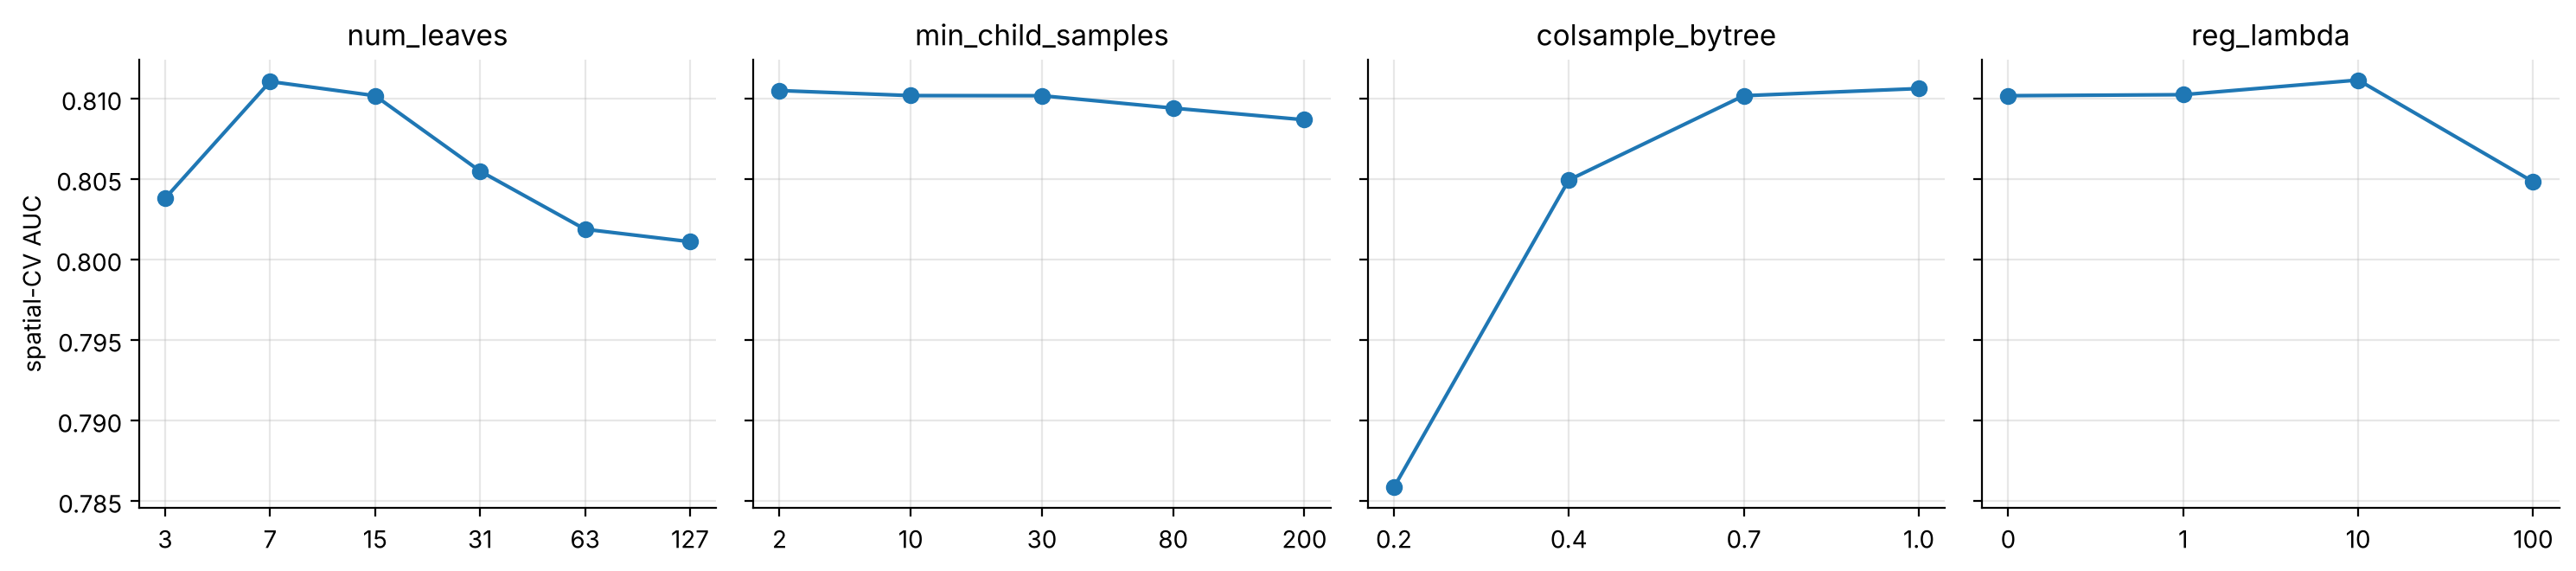

In [3]:
def cv(**kw):
    o = np.zeros(len(y))
    for a, b in folds:
        o[b] = lgb.LGBMClassifier(verbose=-1, random_state=0, **kw).fit(X[a], y[a]).predict_proba(X[b])[:, 1]
    return roc_auc_score(y, o)
base = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=30,
            subsample=0.8, subsample_freq=1, colsample_bytree=0.7)
fig, ax = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for a_, (k, vals) in zip(ax, [("num_leaves", [3, 7, 15, 31, 63, 127]), ("min_child_samples", [2, 10, 30, 80, 200]),
                               ("colsample_bytree", [0.2, 0.4, 0.7, 1.0]), ("reg_lambda", [0, 1, 10, 100])]):
    sc = [cv(**{**base, k: v}) for v in vals]
    a_.plot([str(v) for v in vals], sc, marker="o"); a_.set_title(k)
ax[0].set_ylabel("spatial-CV AUC"); plt.tight_layout(); plt.show()

## Bayesian optimisation with Optuna

Optuna's TPE sampler models which regions of the search space gave good scores and samples there more
often. The project wraps it in **nested** CV (`river_health.experiments.nested_tuning`): each outer fold is
tuned only on its own training catchments, so the reported score includes the cost of tuning.

In [4]:
import optuna; optuna.logging.set_verbosity(optuna.logging.WARNING)
def objective(trial):
    return cv(n_estimators=trial.suggest_int("n_estimators", 100, 600, step=50),
              learning_rate=trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
              num_leaves=trial.suggest_int("num_leaves", 4, 48, log=True),
              min_child_samples=trial.suggest_int("min_child_samples", 10, 120, log=True),
              subsample=trial.suggest_float("subsample", 0.5, 1.0), subsample_freq=1,
              colsample_bytree=trial.suggest_float("colsample_bytree", 0.3, 1.0))
st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=0))
st.optimize(objective, n_trials=25)
print("best (non-nested, so optimistic) AUC:", round(st.best_value, 3)); st.best_params

best (non-nested, so optimistic) AUC: 0.812


{'n_estimators': 200,
 'learning_rate': 0.0594612027220171,
 'num_leaves': 12,
 'min_child_samples': 40,
 'subsample': 0.5093949002181776,
 'colsample_bytree': 0.7323448479531138}

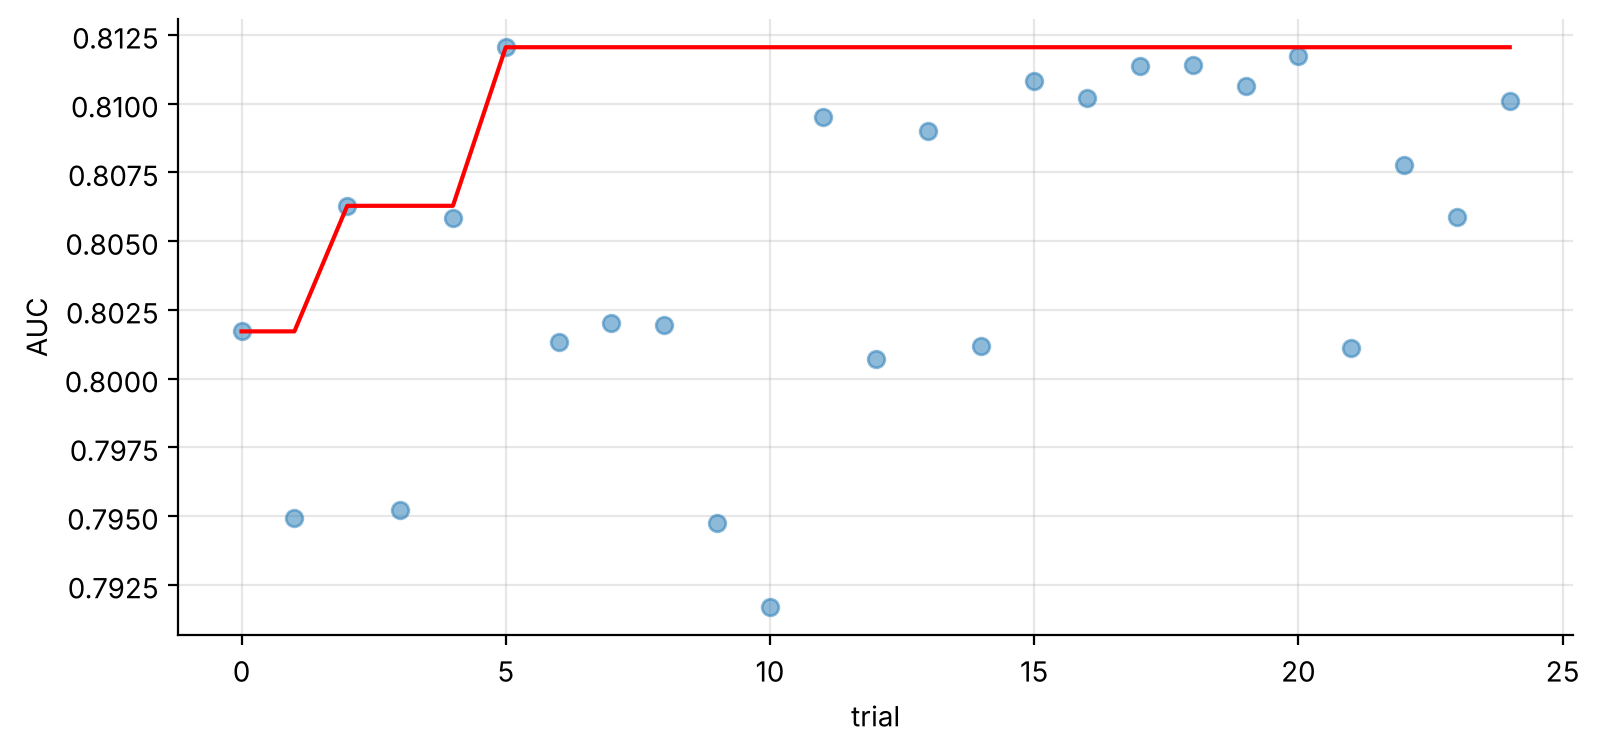

In [5]:
h = st.trials_dataframe()
plt.plot(h.number, h.value, "o", alpha=0.5); plt.plot(h.number, h.value.cummax(), "r-")
plt.xlabel("trial"); plt.ylabel("AUC"); plt.show()

The default-ish baseline is already close to the tuned optimum: on 3,700 rows the choice of features
and folds matters far more than the hyperparameters.